# Phát hiện xe bằng mạng tích chập toàn phần (fully-convolutional) — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/5. Others/2_obj_detection.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| `skimage.io.imread` | `PIL.Image.open` → `np.asarray` |
| `Lambda(lambda x: x/127.5 - 1.)` | dòng `x = x / 127.5 - 1.0` trong `forward` |
| `Conv2D(10,(3,3))`×2 → `MaxPooling2D((8,8))` → `Conv2D(128,(8,8))` → `Conv2D(1,(1,1),'tanh')` | `nn.Conv2d` tương ứng; không có lớp Dense nên mô hình nhận ảnh **kích thước bất kỳ** |
| `model.add(Flatten())` khi train | `out.flatten(1)` khi train |
| `loss='mse', optimizer='adam'`, nhãn +1 / −1 | `nn.MSELoss()`, `torch.optim.Adam(lr=1e-3)` (mặc định Keras), nhãn +1 / −1 |
| `metrics=['accuracy']` (Keras 2.x: `round(ŷ) == y`) | hàm `sign_accuracy`: `torch.round(ŷ) == y` |
| `model.save_weights('localize.h5')` / `get_conv(input_shape=(None,None,3), filename=...)` | `torch.save(state_dict)` / tạo lại mô hình rồi `load_state_dict` |

> Bản gốc dùng `train_test_split(test_size=0.30)` không cố định seed; bản này đặt `random_state=2024` để chạy lại ra cùng kết quả.

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

import glob
from PIL import Image
from sklearn.model_selection import train_test_split

np.random.seed(2024); torch.manual_seed(2024)

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def keras_init(model):
    """Khởi tạo giống mặc định Keras: kernel glorot_uniform, bias = 0
    (PyTorch mặc định dùng kaiming_uniform nên kết quả có thể lệch nhẹ nếu không làm bước này)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    return model

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

# (1) Data
#### Car images: https://drive.google.com/file/d/1rqitUFrFhB84tFVtg1Ad1TVz6coCWpNZ/view?usp=sharing

In [3]:
cars = sorted(glob.glob(str(DATA / "obj_detection" / "vehicles" / "*" / "*.png")))
non_cars = sorted(glob.glob(str(DATA / "obj_detection" / "non-vehicles" / "*" / "*.png")))
Y = np.concatenate([np.ones(len(cars)), np.zeros(len(non_cars)) - 1]).astype(np.float32)   # xe = +1, không phải xe = -1
X = np.array([np.asarray(Image.open(p).convert("RGB")) for p in cars + non_cars])            # (N, 64, 64, 3) uint8
print("cars:", len(cars), "| non-cars:", len(non_cars), "| X:", X.shape)

cars: 8792 | non-cars: 8968 | X: (17760, 64, 64, 3)


In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=2024)
# Keras (N, 64, 64, 3) -> PyTorch (N, 3, 64, 64)
to_t = lambda a: torch.from_numpy(a.transpose(0, 3, 1, 2).astype(np.float32))
X_train_t, X_test_t = to_t(X_train), to_t(X_test)
print("X_train shape:", tuple(X_train_t.shape)); print(len(X_train_t), "train samples"); print(len(X_test_t), "test samples")
train_loader = DataLoader(TensorDataset(X_train_t, torch.from_numpy(Y_train)), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, torch.from_numpy(Y_test)), batch_size=512)

X_train shape: (12432, 3, 64, 64)
12432 train samples
5328 test samples


# (2) Declare model

In [5]:
class GetConv(nn.Module):
    """get_conv() của bản gốc. Toàn bộ là conv nên áp được lên ảnh lớn để tạo heatmap."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 10, 3, padding=1)
        self.conv2 = nn.Conv2d(10, 10, 3, padding=1)
        self.pool = nn.MaxPool2d(8)
        self.drop1 = nn.Dropout(0.25)
        self.dense1 = nn.Conv2d(10, 128, 8)        # "dense" bằng conv 8x8: 8x8 -> 1x1
        self.drop2 = nn.Dropout(0.5)
        self.dense2 = nn.Conv2d(128, 1, 1)

    def forward(self, x):
        x = x / 127.5 - 1.0                         # Lambda(lambda x: x/127.5 - 1.)
        x = F.relu(self.conv2(F.relu(self.conv1(x))))
        x = self.drop1(self.pool(x))
        x = self.drop2(F.relu(self.dense1(x)))
        return torch.tanh(self.dense2(x))           # (B, 1, H', W'); với ảnh 64x64 -> (B, 1, 1, 1)


model = keras_init(GetConv()).to(DEVICE)
summary(model, (3, 64, 64), keras_params=83_367)

Layer                 Type            Output shape                   Param #
conv1                 Conv2d          (1, 10, 64, 64)                    280
conv2                 Conv2d          (1, 10, 64, 64)                    910
pool                  MaxPool2d       (1, 10, 8, 8)                        0
drop1                 Dropout         (1, 10, 8, 8)                        0
dense1                Conv2d          (1, 128, 1, 1)                  82,048
drop2                 Dropout         (1, 128, 1, 1)                       0
dense2                Conv2d          (1, 1, 1, 1)                       129
Total params: 83,367   (Keras gốc: 83,367)


# (3) Train defined model

In [6]:
class Flat(nn.Module):                               # model.add(Flatten()) chỉ dùng khi train
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x).flatten()


def sign_accuracy(out, y):
    return (torch.round(out) == y).float().mean().item()


train_model = Flat(model)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
history = fit(train_model, train_loader, test_loader, 5, optimizer, nn.MSELoss(), sign_accuracy)
score = run_epoch(train_model, test_loader, nn.MSELoss(), sign_accuracy)
print("Test score:", score[0])
print("Test accuracy:", score[1])
OUT_DIR = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)
torch.save(model.state_dict(), OUT_DIR / "localize.pt")    # model.save_weights("localize.h5")

Epoch 1/5 - 15s - loss: 0.4330 - accuracy: 0.5927 - val_loss: 0.1697 - val_accuracy: 0.8315


Epoch 2/5 - 14s - loss: 0.1599 - accuracy: 0.8645 - val_loss: 0.0852 - val_accuracy: 0.9347


Epoch 3/5 - 15s - loss: 0.1064 - accuracy: 0.9194 - val_loss: 0.0559 - val_accuracy: 0.9570


Epoch 4/5 - 13s - loss: 0.0851 - accuracy: 0.9365 - val_loss: 0.0491 - val_accuracy: 0.9623


Epoch 5/5 - 15s - loss: 0.0693 - accuracy: 0.9480 - val_loss: 0.0460 - val_accuracy: 0.9683


Test score: 0.04597137878752417
Test accuracy: 0.9682807816757454


# (4) Evaluate trained model – heatmap trên ảnh lớn `test.jpg`

heatmap shape: (83, 153) | số cửa sổ được coi là xe: 53


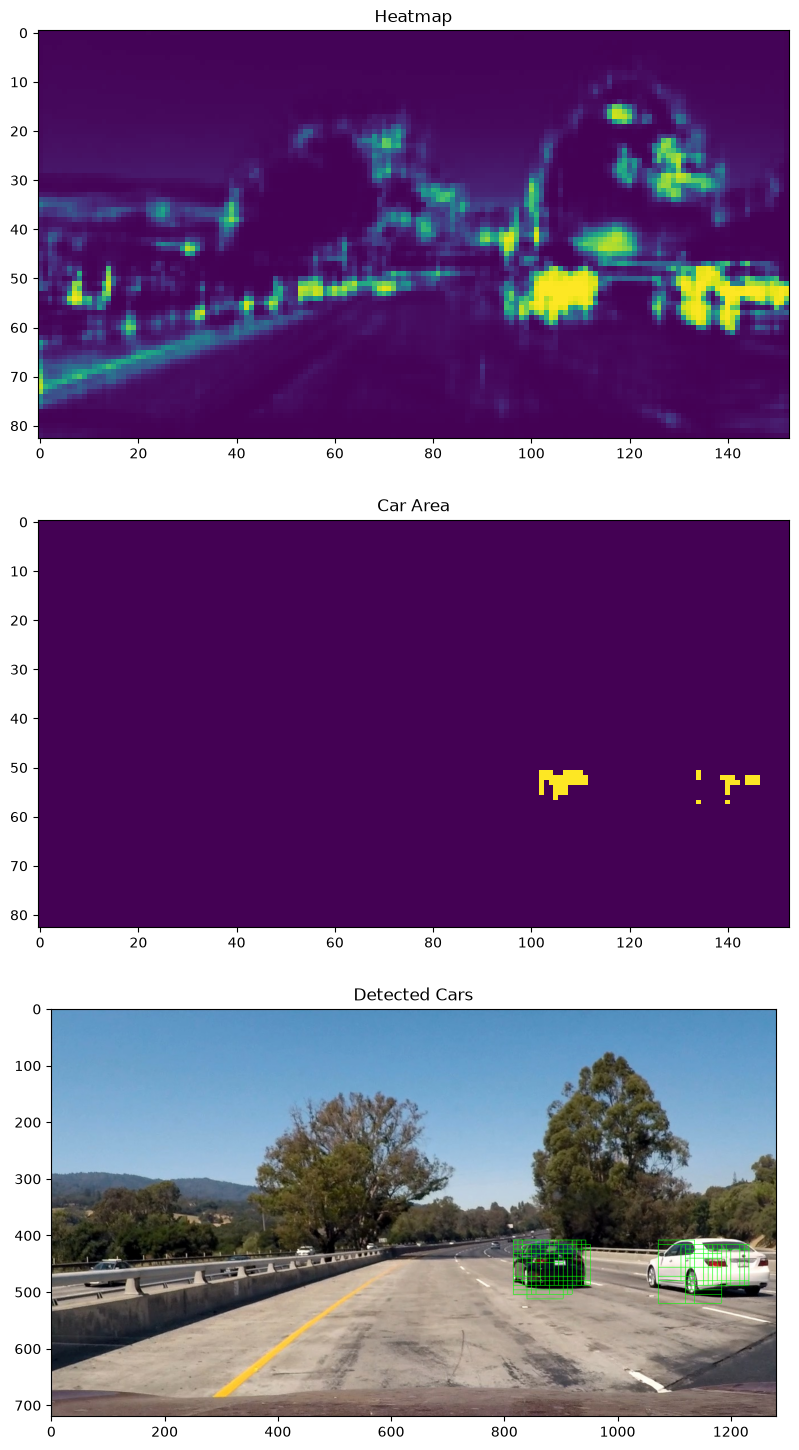

In [7]:
heatmodel = GetConv().to(DEVICE)                     # get_conv(input_shape=(None, None, 3), filename="localize.h5")
heatmodel.load_state_dict(torch.load(OUT_DIR / "localize.pt", map_location=DEVICE))
heatmodel.eval()


def locate(path=DATA / "test.jpg", thr=0.99):
    data = np.array(Image.open(path).convert("RGB"))                    # (720, 1280, 3)
    with torch.no_grad():
        heatmap = heatmodel(torch.from_numpy(data.transpose(2, 0, 1)[None].astype(np.float32)).to(DEVICE))[0, 0].cpu().numpy()
    sel_heatmap = heatmap > thr
    yy, xx = np.nonzero(sel_heatmap)
    H, W = data.shape[:2]
    for j, i in zip(yy, xx):                                            # mỗi điểm heatmap ứng với cửa sổ 64x64, bước 8
        r0, c0 = j * 8, i * 8
        r1, c1 = min(r0 + 64, H - 1), min(c0 + 64, W - 1)               # chặn biên (bản gốc có thể vượt chỉ số ở mép ảnh)
        data[r0:r1, c0] = data[r0:r1, c1] = (0, 255, 0)
        data[r0, c0:c1] = data[r1, c0:c1] = (0, 255, 0)
    return heatmap, sel_heatmap, data


hm, sel_hm, annotated = locate()
print("heatmap shape:", hm.shape, "| số cửa sổ được coi là xe:", int(sel_hm.sum()))
plt.figure(figsize=(10, 18))
for k, (img, t) in enumerate([(hm, "Heatmap"), (sel_hm, "Car Area"), (annotated, "Detected Cars")]):
    plt.subplot(3, 1, k + 1); plt.title(t); plt.imshow(img)
plt.show()